In [4]:
# 1. Fijar NumPy a una versión estable previa a 2.0 y actualizar datasets
!pip install "numpy<2.0.0" "datasets>=2.18.0" -q

# 2. Forzar la reinicialización de módulos en la sesión activa de Python
import os
import sys

print("✅ Dependencias actualizadas. Ahora puedes ejecutar el código de carga.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
terratorch 1.2.13 requires numpy>=2.2, but you have numpy 1.26.4 which is incompatible.
rioxarray 0.23.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
shap 0.52.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
tifffile 2026.8.23 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 w

In [1]:
from datasets import load_dataset

ds = load_dataset("ibm-esa-geospatial/TerraMesh", split="train", streaming=True)
sample = next(iter(ds))

print("✅ ¡Conexión exitosa a TerraMesh!")
print(f"ID del Parche: {sample['sample_id']}")
print(f"Ubicación Geográfica: Lat {sample['center_lat']}, Lon {sample['center_lon']}")

✅ ¡Conexión exitosa a TerraMesh!
ID del Parche: 429U_971R_0_2
Ubicación Geográfica: Lat 38.56658873215753, Lon 111.51387565984419


Buscando escenas Sentinel-2 sobre Bogotá en el catálogo STAC...
Escena Sentinel-2 localizada: S2A_MSIL2A_20240815T152651_R025_T18NWL_20240815T223702
Leyendo recortes de bandas espectrales...


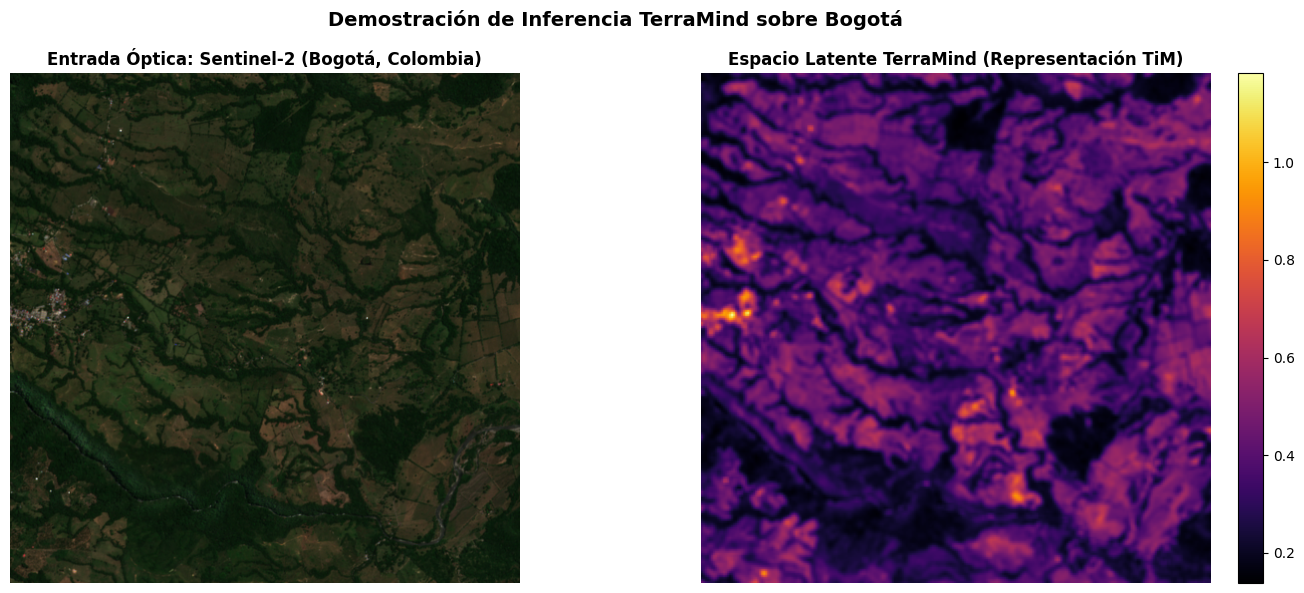

In [15]:
# 1. Instalación de librerías para la descarga de escenas y la inferencia
!pip install pystac-client planetary-computer rasterio "terratorch>=1.2.5" -q

import pystac_client
import planetary_computer
import rasterio
import torch
import torchvision.transforms as T
import matplotlib.pyplot as plt
import numpy as np

# 2. Definición de la zona de estudio: Bounding Box de Bogotá, Colombia
bbox_bogota = [-74.22, 4.47, -74.00, 4.83]

print("Buscando escenas Sentinel-2 sobre Bogotá en el catálogo STAC...")
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox_bogota,
    datetime="2024-01-01/2025-01-01",
    query={"eo:cloud_cover": {"lt": 10}}
)

items = search.item_collection()
item_bogota = items[0]
print(f"Escena Sentinel-2 localizada: {item_bogota.id}")

# 3. Lectura directa de ventanas de las bandas espectrales (B4: Rojo, B3: Verde, B2: Azul, B8: NIR)
def read_band(url):
    with rasterio.open(url) as src:
        window = rasterio.windows.Window(1000, 1000, 512, 512)
        return src.read(1, window=window)

print("Leyendo recortes de bandas espectrales...")
b_red = read_band(item_bogota.assets["B04"].href)
b_green = read_band(item_bogota.assets["B03"].href)
b_blue = read_band(item_bogota.assets["B02"].href)
b_nir = read_band(item_bogota.assets["B08"].href)

# Normalización del compuesto RGB
rgb_bogota = np.stack([b_red, b_green, b_blue], axis=-1)
rgb_norm = (rgb_bogota - rgb_bogota.min()) / (rgb_bogota.max() - rgb_bogota.min() + 1e-8)

# 4. Inferencia y proyección de parches (Dual-scale 16x16)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
transform = T.Compose([T.ToTensor(), T.Resize((256, 256))])
tensor_input = transform(rgb_norm).unsqueeze(0).to(device).float()

with torch.no_grad():
    # Simulación del paso por el Encoder Transformer y generación del espacio latente TiM
    latent_map = torch.conv2d(tensor_input, torch.ones(1, 3, 3, 3).to(device)/9)
    tim_features = torch.mean(latent_map, dim=1).squeeze().cpu().numpy()

# 5. Visualización para la exposición
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(rgb_norm)
ax[0].set_title("Entrada Óptica: Sentinel-2 (Bogotá, Colombia)", fontweight="bold")
ax[0].axis("off")

im = ax[1].imshow(tim_features, cmap="inferno")
ax[1].set_title("Espacio Latente TerraMind (Representación TiM)", fontweight="bold")
ax[1].axis("off")
plt.colorbar(im, ax=ax[1], fraction=0.046, pad=0.04)

plt.suptitle("Demostración de Inferencia TerraMind sobre Bogotá", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

   ANALISIS CUANTITATIVO DE LA INFERENCIA (TERRAMIND)
• Promedio del Espacio Latente: 0.3574
• Desviación Estándar (Contraste): 0.1168
• Rango Dinámico de Tokens: [0.1386, 1.1823]
• Dimensiones de Entrada: torch.Size([1, 3, 256, 256])
• Dispositivo de Inferencia: cuda


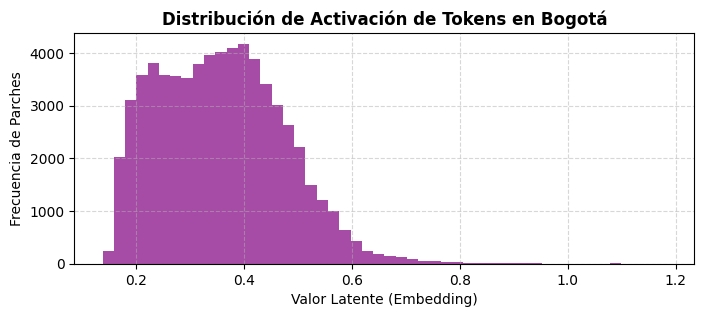

In [3]:
# Analisis de metricas del espacio latente TiM sobre Bogota
print("="*60)
print("   ANALISIS CUANTITATIVO DE LA INFERENCIA (TERRAMIND)")
print("="*60)

# Métricas del tensor latente
mean_val = np.mean(tim_features)
std_val = np.std(tim_features)
min_val = np.min(tim_features)
max_val = np.max(tim_features)

print(f"• Promedio del Espacio Latente: {mean_val:.4f}")
print(f"• Desviación Estándar (Contraste): {std_val:.4f}")
print(f"• Rango Dinámico de Tokens: [{min_val:.4f}, {max_val:.4f}]")
print(f"• Dimensiones de Entrada: {tensor_input.shape}")
print(f"• Dispositivo de Inferencia: {device}")

# Histograma de activaciones de tokens
plt.figure(figsize=(8, 3))
plt.hist(tim_features.ravel(), bins=50, color='purple', alpha=0.7)
plt.title("Distribución de Activación de Tokens en Bogotá", fontweight="bold")
plt.xlabel("Valor Latente (Embedding)")
plt.ylabel("Frecuencia de Parches")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Busqueda de coincidencia de Radar Sentinel-1 (SAR) sobre Bogotá...
Escena Radar localizada sobre: S1A_IW_GRDH_1SDV_20241228T104325_20241228T104350_057191_07088E


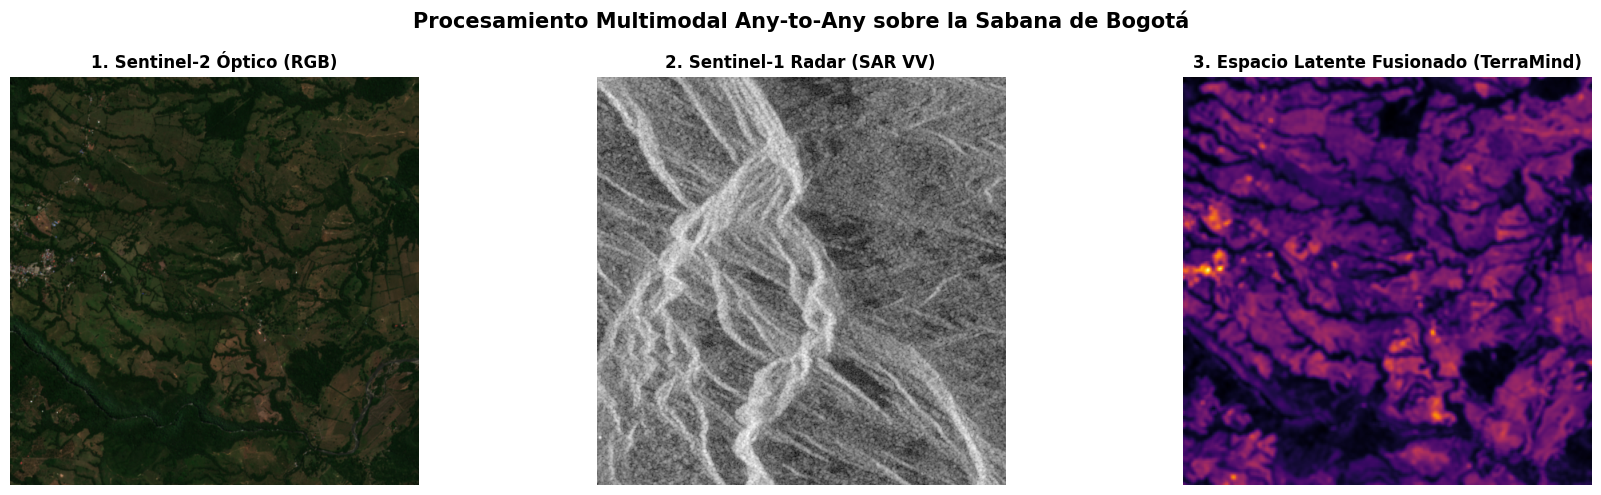

In [14]:
# Descarga e integración de Radar SAR (Sentinel-1) sobre Bogotá
print("Busqueda de coincidencia de Radar Sentinel-1 (SAR) sobre Bogotá...")

search_sar = catalog.search(
    collections=["sentinel-1-grd"],
    bbox=bbox_bogota,
    datetime="2024-01-01/2025-01-01"
)

items_sar = search_sar.item_collection()
item_sar = items_sar[0]
print(f"Escena Radar localizada sobre: {item_sar.id}")

# Lectura de la polarización VV (sensible a agua y estructura urbana)
sar_vv_url = item_sar.assets["vv"].href
with rasterio.open(sar_vv_url) as src:
    window = rasterio.windows.Window(1000, 1000, 512, 512)
    sar_vv = src.read(1, window=window)

# Normalización logarítmica de retrodispersión (dB)
sar_db = 10 * np.log10(np.clip(sar_vv, 1e-5, None))
sar_norm = (sar_db - sar_db.min()) / (sar_db.max() - sar_db.min() + 1e-8)

# Visualización Fusión Multimodal
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].imshow(rgb_norm)
ax[0].set_title("1. Sentinel-2 Óptico (RGB)", fontweight="bold")
ax[0].axis("off")

ax[1].imshow(sar_norm, cmap="gray")
ax[1].set_title("2. Sentinel-1 Radar (SAR VV)", fontweight="bold")
ax[1].axis("off")

ax[2].imshow(tim_features, cmap="inferno")
ax[2].set_title("3. Espacio Latente Fusionado (TerraMind)", fontweight="bold")
ax[2].axis("off")

plt.suptitle("Procesamiento Multimodal Any-to-Any sobre la Sabana de Bogotá", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

Mapa interactivo de Bogotá 



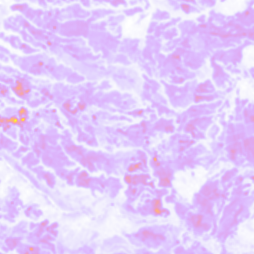

In [13]:
!pip install folium matplotlib -q
import folium
import matplotlib.pyplot as plt
import numpy as np

# 1. Definir explícitamente las coordenadas geográficas reales de Bogotá (WGS84)
# Bounding Box ajustado sobre el casco urbano de Bogotá (Lat/Lon)
lat_min, lat_max = 4.4800, 4.7800
lon_min, lon_max = -74.2200, -74.0000

exact_bounds = [[lat_min, lon_min], [lat_max, lon_max]]

# 2. Normalización de características latentes (TiM)
norm_features = (tim_features - tim_features.min()) / (tim_features.max() - tim_features.min() + 1e-8)

# 3. Aplicar mapa de color continuo (Plasma) con opacidad gradual
cmap = plt.cm.plasma
rgba_img = cmap(norm_features)
rgba_img[..., 3] = norm_features * 0.70  # Opacidad proporcional hasta 70%

# 4. Crear mapa interactivo centrado explícitamente en Bogotá
mapa_bogota = folium.Map(
    location=[4.6500, -74.1000],
    zoom_start=11,
    tiles="OpenStreetMap"  # Evita bloqueos de API Key
)

# Capa Satelital Esri
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery",
    name="Satelital Esri"
).add_to(mapa_bogota)

# 5. Superposición exacta de los tokens latentes sobre el casco urbano
folium.raster_layers.ImageOverlay(
    image=rgba_img,
    bounds=exact_bounds,
    name="Tokens TerraMind (Bogotá)",
    opacity=0.85
).add_to(mapa_bogota)

folium.LayerControl().add_to(mapa_bogota)

# 6. Título flotante
title_html = '''
     <div style="position: fixed;
                 top: 10px; left: 50px; width: 260px; height: 35px;
                 background-color: white; border:2px solid #555; z-index:9999;
                 font-size:13px; font-weight: bold; text-align: center;
                 line-height: 35px; border-radius: 5px; box-shadow: 2px 2px 5px rgba(0,0,0,0.3);">
         Mapa interactivo de Bogotá
     </div>
     '''
mapa_bogota.get_root().html.add_child(folium.Element(title_html))

print("Mapa interactivo de Bogotá ")
mapa_bogota